# 02 — Storage format and layout experiments

BFT65B · Student ID 11230945

Measure uncompressed CSV against flat and year/quarter partitioned Parquet using Snappy and ZSTD. Verify equality before timing. The source is the sealed acquisition from Notebook 01.

## 1. Repository and pinned runtime

In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    actual = subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip()
    if actual != REPO_URL:
        raise RuntimeError(f"Unexpected repository: {actual}")
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(REPO / "requirements.txt")], check=True)
# The research commands run in fresh Python processes to avoid stale imports.
def command(*args):
    subprocess.run([sys.executable, str(REPO / "run_part1.py"), *map(str, args)], cwd=REPO, check=True)


Git revision: 69f82abd7df779ade73bcde8d93c261781b5e1e5


## 2. Mandatory offline validation

In [2]:
import tempfile
import xml.etree.ElementTree as ET

TESTS_PASSED = False
with tempfile.TemporaryDirectory() as tmp:
    result_path = Path(tmp) / "tests.xml"
    env = dict(os.environ, PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")
    # Stream the complete failure traceback instead of truncating captured output.
    subprocess.run([sys.executable, "-m", "pytest", "-q", "--tb=short",
                    "--show-capture=no", f"--junitxml={result_path}"],
                   cwd=REPO, env=env, check=True)
    suites = ET.parse(result_path).findall(".//testsuite")
    total = sum(int(s.get("tests", 0)) for s in suites)
    skipped = sum(int(s.get("skipped", 0)) for s in suites)
    if total == 0 or skipped:
        raise RuntimeError(f"Incomplete tests: total={total}, skipped={skipped}")
    TESTS_PASSED = True
    print(f"Mandatory offline validation: PASS ({total} tests, zero skips)")


Mandatory offline validation: PASS (51 tests, zero skips)


## 3. Resolve the verified source

In [3]:
from google.colab import drive
import json

drive.mount("/content/drive")
WORKSPACE = Path("/content/drive/MyDrive/11230945")
WORKSPACE.mkdir(parents=True, exist_ok=True)
print("Workspace:", WORKSPACE)


Mounted at /content/drive
Workspace: /content/drive/MyDrive/11230945


In [4]:
assert TESTS_PASSED
assert not (WORKSPACE / "pending_source.json").exists(), "Complete Notebook 01 first"
command("verify", "--workspace", WORKSPACE)
source_pointer = json.loads((WORKSPACE / "active_source.json").read_text())
print("Source manifest SHA-256:", source_pointer["manifest_sha256"])


Source manifest SHA-256: e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e


## 4. Experimental protocol

| Factor | Levels |
|---|---|
| Storage representation | CSV; flat Snappy/ZSTD; partitioned Snappy/ZSTD |
| Workload | Full scan; six-column projection; 2020; 2020Q1 |
| Codec | Snappy default; ZSTD level 3 |
| Repetition | 1 warm-up and 5 measured runs for each pair |
| Supplemental study | pandas versus Polars, same four-column CSV projection |

All files are staged on Colab local disk. The worker reads the same logical columns, checks equivalent outputs, and records fresh-process RSS. Partition filters include explicit year/quarter predicates; candidate fragments are not physical bytes read. OS caching is not controlled. Imports and process startup are excluded from query timing. Preparation, full equality comparisons and plots are not timed.

In [5]:
import shutil

LOCAL = Path("/content/fdic_benchmark_scratch")
LOCAL.mkdir(exist_ok=True)
print("Free local disk (GiB):", round(shutil.disk_usage(LOCAL).free / 2**30, 2))
if shutil.disk_usage(LOCAL).free < 5 * 2**30:
    raise RuntimeError("Insufficient scratch disk; free at least 5 GiB before benchmarking")
WARMUPS, REPETITIONS, THREADS = 1, 5, 2
print("Expected worker executions:", (5*4+2)*(WARMUPS+REPETITIONS))


Free local disk (GiB): 107.04
Expected worker executions: 132


## 5. Prepare formats, check parity and run benchmark
The command stages the representations, compares values and null masks for every workload, runs the randomized measurement blocks and copies the evidence to Drive only after all checks pass. A failed run does not publish a new evidence pointer.

In [6]:
assert TESTS_PASSED
BENCHMARK_COMPLETED = False
command("benchmark", "--workspace", WORKSPACE, "--local", LOCAL,
        "--warmups", WARMUPS, "--repetitions", REPETITIONS, "--threads", THREADS)
BENCHMARK_COMPLETED = True


## 6. Verify the saved evidence
Check linkage, evidence hashes, trial counts and equivalence. Reject a stale benchmark from another acquisition.

In [7]:
import hashlib
assert BENCHMARK_COMPLETED
pointer = json.loads((WORKSPACE / "active_storage.json").read_text())
EVIDENCE = WORKSPACE / pointer["path"]
def digest(path):
    with path.open("rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()
assert pointer["evidence_sha256"] == digest(EVIDENCE / "evidence.json")
result = json.loads((EVIDENCE / "evidence.json").read_text())
current_source = json.loads((WORKSPACE / "active_source.json").read_text())
assert result["status"] == "PASS"
assert result["source_manifest_sha256"] == current_source["manifest_sha256"]
assert result["total_trials"] == 22*(WARMUPS+REPETITIONS)
assert result["measured_trials"] == 22*REPETITIONS
for filename, expected in result["files"].items():
    assert digest(EVIDENCE / filename) == expected, filename
print("Storage evidence verified:", EVIDENCE.name)
print("Measured trials:", result["measured_trials"])


Storage evidence verified: 2026-11-25T175908_228969Z_684c5cac
Measured trials: 110


## 7. Measured results
Use the actual tables below to justify storage choices. Compare flat versus partitioned layouts within a codec, Snappy versus ZSTD within a layout, and CSV against both. Consider query latency, size and whole-worker memory together.

**Table 1. Storage footprint by format and layout**

| Storage format | Size (bytes) | Size (MiB) | Reduction vs CSV (%) |
| --- | ---: | ---: | ---: |
| CSV | 371,665,731 | 354.45 | 0.00 |
| Flat Snappy | 222,080,567 | 211.79 | 40.25 |
| Flat ZSTD | 187,273,492 | 178.60 | 49.61 |
| Partitioned Snappy | 255,258,245 | 243.43 | 31.32 |
| Partitioned ZSTD | 201,351,704 | 192.02 | 45.82 |

**Table 2. Read latency and peak worker memory**

| Storage format | Workload | Trials | Median (s) | IQR (s) | Peak RSS (MiB) | Rows |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| CSV | Full scan | 5 | 4.0164 | 1.7035 | 4,161.66 | 1,682,739 |
| CSV | Column projection | 5 | 1.9802 | 1.0559 | 4,161.66 | 1,682,739 |
| CSV | Quarter filter (2020Q1) | 5 | 1.9205 | 0.0919 | 4,161.66 | 5,182 |
| CSV | Year filter (2020) | 5 | 1.9762 | 0.3018 | 4,161.66 | 20,478 |
| Flat Snappy | Full scan | 5 | 1.1430 | 0.0369 | 4,161.66 | 1,682,739 |
| Flat Snappy | Column projection | 5 | 0.2281 | 0.0301 | 4,161.66 | 1,682,739 |
| Flat Snappy | Quarter filter (2020Q1) | 5 | 0.0310 | 0.0029 | 4,161.66 | 5,182 |
| Flat Snappy | Year filter (2020) | 5 | 0.0297 | 0.0116 | 4,161.66 | 20,478 |
| Flat ZSTD | Full scan | 5 | 1.2801 | 0.6087 | 4,161.66 | 1,682,739 |
| Flat ZSTD | Column projection | 5 | 0.2145 | 0.0313 | 4,161.66 | 1,682,739 |
| Flat ZSTD | Quarter filter (2020Q1) | 5 | 0.0314 | 0.0112 | 4,161.66 | 5,182 |
| Flat ZSTD | Year filter (2020) | 5 | 0.0306 | 0.0160 | 4,161.66 | 20,478 |
| Partitioned Snappy | Full scan | 5 | 1.4919 | 0.1865 | 4,161.66 | 1,682,739 |
| Partitioned Snappy | Column projection | 5 | 0.4114 | 0.0920 | 4,161.66 | 1,682,739 |
| Partitioned Snappy | Quarter filter (2020Q1) | 5 | 0.0169 | 0.0005 | 4,161.66 | 5,182 |
| Partitioned Snappy | Year filter (2020) | 5 | 0.0227 | 0.0016 | 4,161.66 | 20,478 |
| Partitioned ZSTD | Full scan | 5 | 1.6436 | 0.0542 | 4,161.66 | 1,682,739 |
| Partitioned ZSTD | Column projection | 5 | 0.4128 | 0.1630 | 4,161.66 | 1,682,739 |
| Partitioned ZSTD | Quarter filter (2020Q1) | 5 | 0.0192 | 0.0087 | 4,161.66 | 5,182 |
| Partitioned ZSTD | Year filter (2020) | 5 | 0.0236 | 0.0123 | 4,161.66 | 20,478 |

**Table 3. Supplementary CSV reader comparison**

| Engine | Trials | Median (s) | IQR (s) | Peak RSS (MiB) |
| --- | ---: | ---: | ---: | ---: |
| pandas | 5 | 5.3613 | 1.3842 | 4,161.66 |
| Polars | 5 | 0.7283 | 0.4536 | 4,161.66 |

**Table 4. Partition pruning by workload**

| Storage format | Workload | Candidate fragments | Total fragments | Rows |
| --- | --- | ---: | ---: | ---: |
| Partitioned Snappy | Full scan | 170 | 170 | 1,682,739 |
| Partitioned Snappy | Column projection | 170 | 170 | 1,682,739 |
| Partitioned Snappy | Quarter filter (2020Q1) | 1 | 170 | 5,182 |
| Partitioned Snappy | Year filter (2020) | 4 | 170 | 20,478 |
| Partitioned ZSTD | Full scan | 170 | 170 | 1,682,739 |
| Partitioned ZSTD | Column projection | 170 | 170 | 1,682,739 |
| Partitioned ZSTD | Quarter filter (2020Q1) | 1 | 170 | 5,182 |
| Partitioned ZSTD | Year filter (2020) | 4 | 170 | 20,478 |

**Figure 1. Storage footprint by format and layout (MiB)**

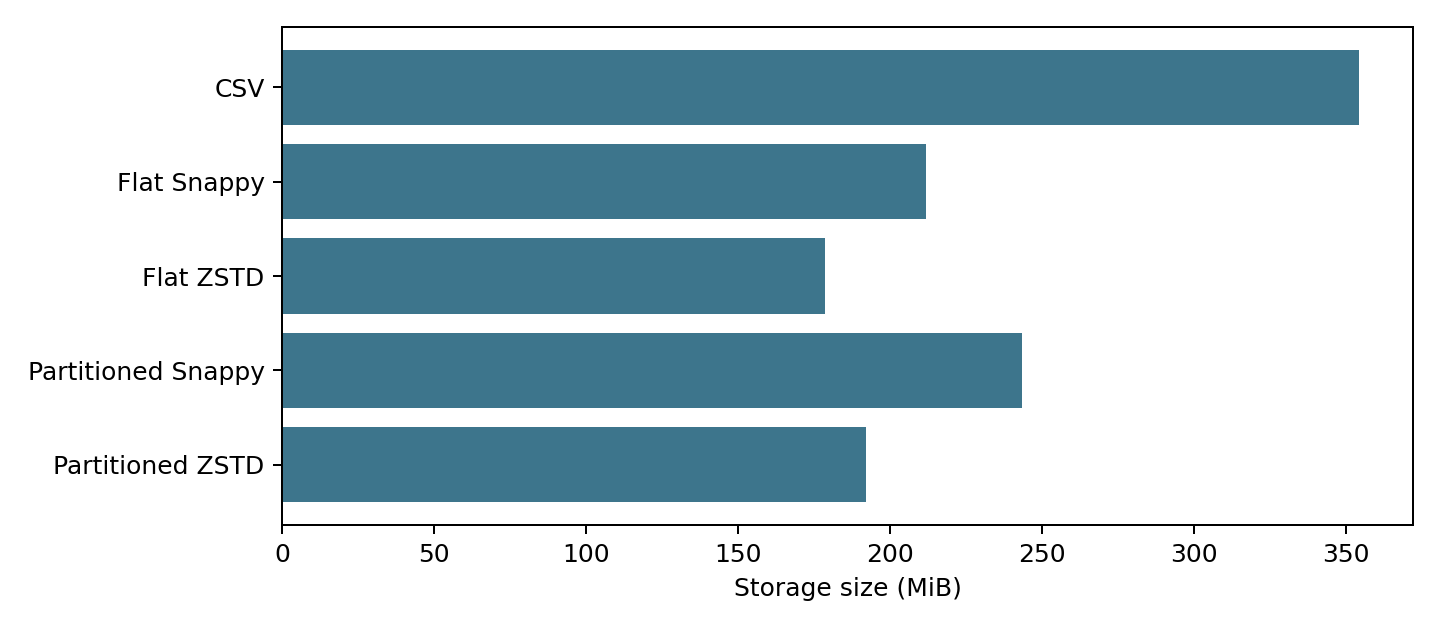

**Figure 2. Median query latency by workload (s)**

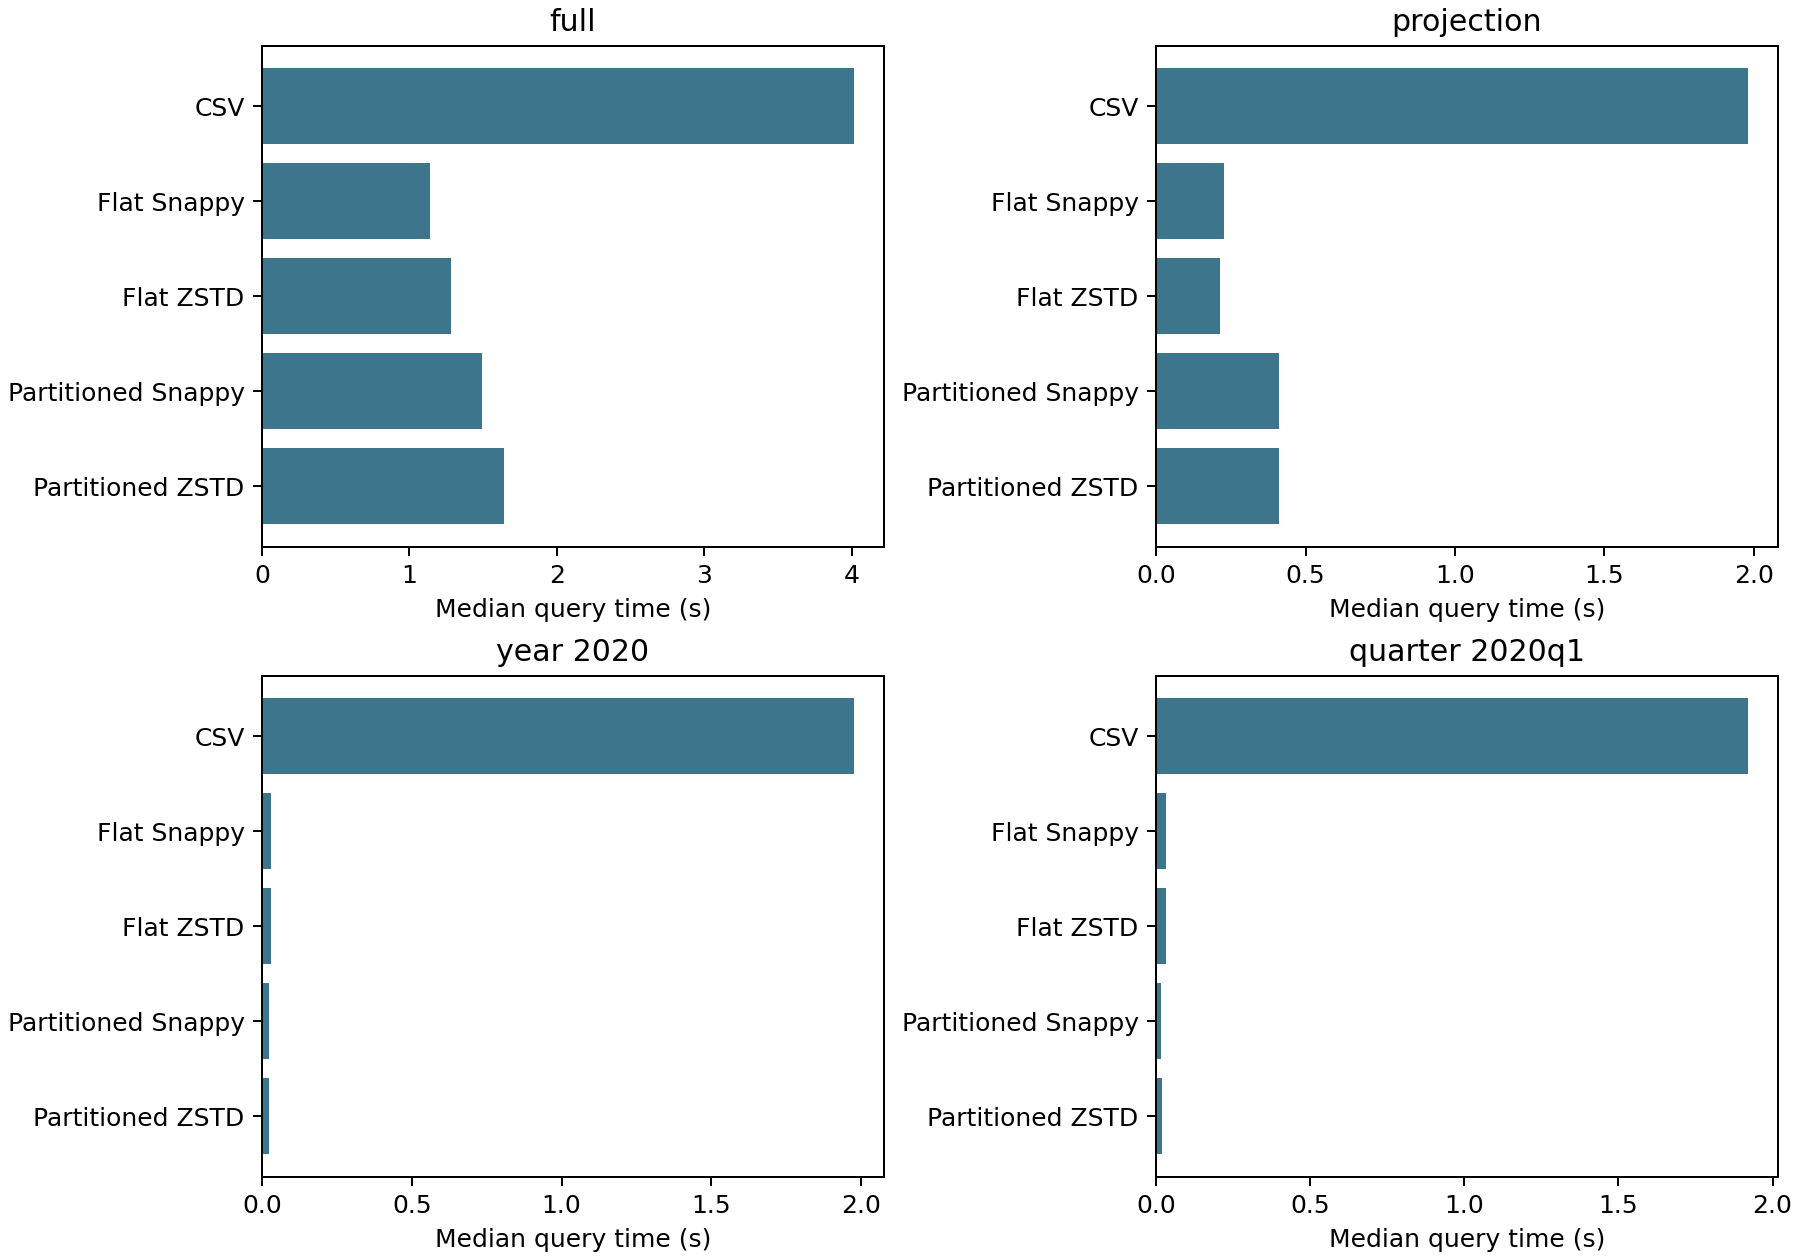

**Figure 3. Median peak worker RSS by workload (MiB)**

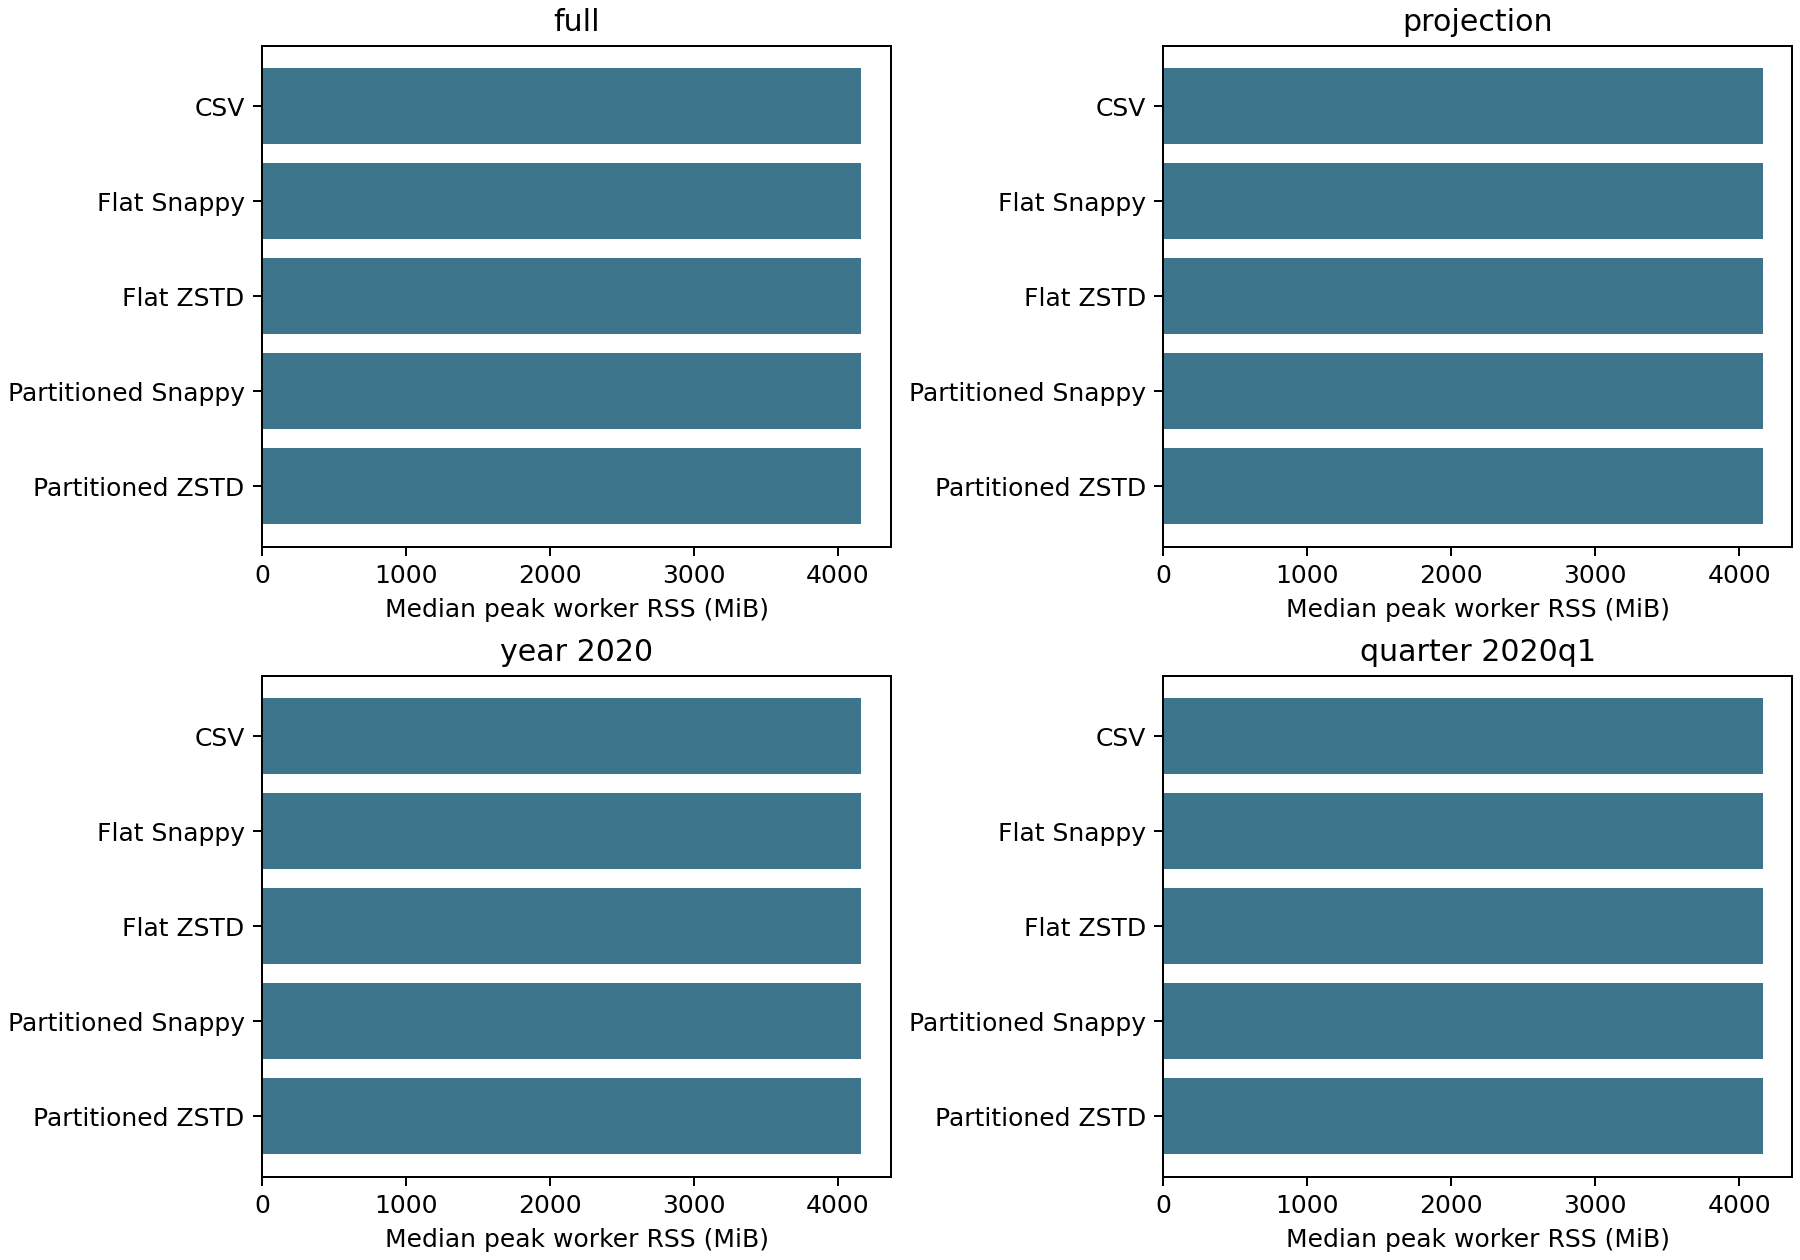

*All statistics and figures are retrieved from the verified experimental evidence. Figure dimensions are adjusted for notebook readability only.*

In [11]:

import csv
from IPython.display import display, Markdown, HTML, Image

FORMAT_NAMES = {
    "csv": "CSV",
    "flat_snappy": "Flat Snappy",
    "flat_zstd": "Flat ZSTD",
    "partitioned_snappy": "Partitioned Snappy",
    "partitioned_zstd": "Partitioned ZSTD",
    "pandas": "pandas",
    "polars": "Polars",
}

WORKLOAD_NAMES = {
    "full": "Full scan",
    "projection": "Column projection",
    "year_2020": "Year filter (2020)",
    "quarter_2020q1": "Quarter filter (2020Q1)",
}

INTEGER_FIELDS = {
    "bytes", "n", "rows",
    "candidate_fragments", "total_fragments"
}

DECIMAL_FIELDS = {
    "mib": 2,
    "reduction_vs_csv_pct": 2,
    "median_seconds": 4,
    "iqr_seconds": 4,
    "median_peak_rss_mib": 2,
}


def format_value(key, value):
    if value in ("", None):
        return "—"
    if key == "format":
        return FORMAT_NAMES.get(value, value)
    if key == "workload":
        return WORKLOAD_NAMES.get(value, value)
    if key in INTEGER_FIELDS:
        return f"{int(value):,}"
    if key in DECIMAL_FIELDS:
        return f"{float(value):,.{DECIMAL_FIELDS[key]}f}"
    return str(value)


def show_table(title, filename, columns, where=None):
    with (EVIDENCE / filename).open(
        newline="", encoding="utf-8"
    ) as f:
        rows = list(csv.DictReader(f))

    if where is not None:
        rows = [row for row in rows if where(row)]

    display(Markdown(f"**{title}**"))

    header = "| " + " | ".join(columns.values()) + " |"

    divider = "| " + " | ".join(
        "---:" if key in INTEGER_FIELDS
        or key in DECIMAL_FIELDS else "---"
        for key in columns
    ) + " |"

    body = [
        "| " + " | ".join(
            format_value(key, row[key])
            for key in columns
        ) + " |"
        for row in rows
    ]

    display(Markdown("\n".join([header, divider, *body])))
    display(HTML('<div style="height:22px"></div>'))


# Storage footprint
show_table(
    "Table 1. Storage footprint by format and layout",
    "sizes.csv",
    {
        "format": "Storage format",
        "bytes": "Size (bytes)",
        "mib": "Size (MiB)",
        "reduction_vs_csv_pct": "Reduction vs CSV (%)",
    },
)


# Read performance
show_table(
    "Table 2. Read latency and peak worker memory",
    "summary.csv",
    {
        "format": "Storage format",
        "workload": "Workload",
        "n": "Trials",
        "median_seconds": "Median (s)",
        "iqr_seconds": "IQR (s)",
        "median_peak_rss_mib": "Peak RSS (MiB)",
        "rows": "Rows",
    },
    where=lambda r: r["workload"] != "csv_projection",
)


# Supplementary reader comparison
show_table(
    "Table 3. Supplementary CSV reader comparison",
    "summary.csv",
    {
        "format": "Engine",
        "n": "Trials",
        "median_seconds": "Median (s)",
        "iqr_seconds": "IQR (s)",
        "median_peak_rss_mib": "Peak RSS (MiB)",
    },
    where=lambda r: r["workload"] == "csv_projection",
)


# Partition pruning evidence
show_table(
    "Table 4. Partition pruning by workload",
    "summary.csv",
    {
        "format": "Storage format",
        "workload": "Workload",
        "candidate_fragments": "Candidate fragments",
        "total_fragments": "Total fragments",
        "rows": "Rows",
    },
    where=lambda r: r["format"].startswith("partitioned"),
)


# Figures
for caption, filename in (
    (
        "Figure 1. Storage footprint by format and layout (MiB)",
        "storage_size.png",
    ),
    (
        "Figure 2. Median query latency by workload (s)",
        "latency.png",
    ),
    (
        "Figure 3. Median peak worker RSS by workload (MiB)",
        "memory.png",
    ),
):
    display(Markdown(f"**{caption}**"))
    display(Image(
        filename=str(EVIDENCE / filename),
        width=680
    ))
    display(HTML('<div style="height:22px"></div>'))


display(Markdown(
    "*All statistics and figures are retrieved from the "
    "verified experimental evidence. Figure dimensions "
    "are adjusted for notebook readability only.*"
))


## 8. Partition pruning verification and interpretation
The year and quarter queries should select four and one candidate files from the 170 partitioned files. The flat representation may still exploit row-group statistics. A lower candidate-file count is not itself a measured reduction in physical I/O.

In [9]:
with (EVIDENCE / "summary.csv").open(newline="", encoding="utf-8") as f:
    summary = list(csv.DictReader(f))
for row in summary:
    if row["format"].startswith("partitioned"):
        expected = {"year_2020": 4, "quarter_2020q1": 1}.get(row["workload"], 170)
        assert int(row["candidate_fragments"]) == expected
        assert int(row["total_fragments"]) == 170
print("Partition candidate-file checks: PASS")


Partition candidate-file checks: PASS


## 9. Handoff
Part 1 is complete only when source and benchmark gates pass. Save the executed notebook with its actual outputs. Part 2 reads the Bronze source; the benchmark replicas are temporary and do not enter the model. The report should discuss the measured trade-offs and distinguish local CPU experiments from distributed scaling evidence.